# **2. Limpieza de Datos, Preparación y Control de Data Leakage**
**Objetivo de este cuaderno:**
1. Cargar modularmente los datos crudos a través de `src/data.py`.
2. Aplicar los criterios de limpieza y filtrado de anomalías justificadas en el EDA inicial.
3. Garantizar el control estricto de **Data Leakage** eliminando todas las variables posteriores al inicio del viaje.
4. Generar e inspeccionar nuevas variables predictivas (temporales, cíclicas y espaciales) con `src/features.py`.
5. Exportar el dataset procesado a `data/processed/` para abastecer las fases de partición, evaluación y modelado.

## 2.1. Importación de Librerías y Módulos del Proyecto
Importamos las librerías necesarias y las funciones modulares desarrolladas en `src/`.

In [18]:
import os

import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_raw_data, clean_data, get_data_dir
from src.features import FeatureExtractor


## 2.2. Carga de Datos Crudos
Utilizamos la función `load_raw_data` de `src/data.py`. Para asegurar que los modelos posteriores puedan entrenarse sin agotar la memoria RAM y manteniendo plena representatividad estadística, tomamos una muestra balanceada del 10% de cada mes (más de 300 mil viajes distribuidos homogéneamente en los tres meses).

In [19]:
# Carga de muestra representativa balanceada de los 3 meses
df_raw = load_raw_data(sample_fraction=0.10, random_state=42)
print(f'Dimensiones de los datos crudos cargados: {df_raw.shape[0]:,} filas y {df_raw.shape[1]} columnas.')
df_raw.head()

Dimensiones de los datos crudos cargados: 1,107,721 filas y 20 columnas.


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,1,2026-01-18 12:35:13,2026-01-18 12:46:05,1.0,3.90,1.0,N,68,238,1,17.00,3.25,0.5,2.50,0.00,1.0,24.25,2.5,0.0,0.75
1,2,2026-01-28 01:01:57,2026-01-28 01:34:45,NaN,13.95,NaN,NaN,69,61,0,49.13,0.00,0.5,0.00,7.46,1.0,58.09,NaN,NaN,0.00
2,2,2026-01-09 10:35:27,2026-01-09 11:05:50,1.0,13.79,1.0,N,13,138,1,55.50,5.00,0.5,19.57,0.00,1.0,84.82,2.5,0.0,0.75
3,2,2026-01-24 22:26:51,2026-01-24 22:37:03,1.0,1.76,1.0,N,164,79,2,11.40,1.00,0.5,0.00,0.00,1.0,17.15,2.5,0.0,0.75
4,2,2026-01-01 01:59:23,2026-01-01 02:13:41,NaN,7.42,NaN,NaN,74,232,0,41.06,0.00,0.5,0.00,0.00,1.0,45.81,NaN,NaN,0.75


## 2.3. Limpieza de Datos y Tratamiento de Anomalías
Aplicamos `clean_data` de `src/data.py`, el cual ejecuta:
1. **Cálculo de la variable objetivo:** `trip_duration` (en minutos).
2. **Filtrado de anomalías de duración:** viajes entre 1 minuto y 120 minutos (2 horas).
3. **Filtrado de capacidad de pasajeros:** viajes entre 1 y 6 pasajeros.
4. **Validación de zonas TLC:** códigos de origen (`PULocationID`) y destino (`DOLocationID`) válidos (1 a 265).
5. **Eliminación de data leakage:** se eliminaron las columnas que producen fuga de datos descritas anteriormente.

In [20]:
n_antes = len(df_raw)
df_clean = clean_data(df_raw)
n_despues = len(df_clean)
descartados = n_antes - n_despues
pct_descartado = (descartados / n_antes) * 100

print(f'Registros antes de limpieza  : {n_antes:,}')
print(f'Registros limpios válidos    : {n_despues:,}')
print(f'Registros descartados/outlier: {descartados:,} ({round(pct_descartado,2)}%)')

Registros antes de limpieza  : 1,107,721
Registros limpios válidos    : 773,167
Registros descartados/outlier: 334,554 (30.2%)


Observamos las estadística de la variable objetivo

In [21]:
print('Estadística de trip_duration:')
df_clean['trip_duration'].describe()

Estadística de trip_duration:


count    773167.000000
mean         17.202944
std          14.813672
min           1.000000
25%           7.733333
50%          12.766667
75%          21.166667
max         120.000000
Name: trip_duration, dtype: float64

## 2.4. Control de Data Leakage (Fuga de Datos)
A continuación, confirmaremos que las varaibles con data leakage hayan sido eliminadas.

In [22]:
df_clean

,VendorID,tpep_pickup_datetime,passenger_count,PULocationID,DOLocationID,trip_duration
0,1,2026-01-18 12:35:13,1.0,68,238,10.866667
2,2,2026-01-09 10:35:27,1.0,13,138,30.383333
3,2,2026-01-24 22:26:51,1.0,164,79,10.200000
5,2,2026-01-27 09:30:30,2.0,141,262,13.600000
7,2,2026-01-22 21:18:42,1.0,229,238,13.666667
...,...,...,...,...,...,...
1107714,2,2026-03-04 18:53:21,1.0,162,263,7.816667
1107715,1,2026-03-27 14:15:37,1.0,237,145,10.250000
1107716,2,2026-03-09 16:14:48,1.0,138,61,57.033333
1107719,2,2026-03-30 11:31:32,3.0,43,239,4.566667


Solo se encuentran las 5 columnas que no producen fuga de datos y el target

## 2.5. Ingeniería de Características (Feature Engineering)
Utilizamos `FeatureExtractor` de `src/features.py`, el cual transforma el dataset agregando variables sin riesgo de leakage:
- **`pickup_hour`**: Hora del día (0 a 23).
- **`pickup_dayofweek`**: Día de la semana (0=Lunes, 6=Domingo).
- **`pickup_month`**: Mes del viaje (1=Enero, 2=Febrero, 3=Marzo).
- **`is_weekend`**: Variable binaria (1 si es sábado o domingo, 0 si no).
- **`is_rush_hour`**: Indicador de hora punta laboral (7-9 AM y 16-19 PM en días hábiles).
- **`sin_hour` y `cos_hour`**: Transformaciones periódicas continuas que preservan la continuidad circular de las horas.
- **`is_airport`**: Variable binaria para viajes con origen o destino en aeropuertos (JFK, LGA, EWR).

In [23]:
fe = FeatureExtractor()
df_features = fe.transform(df_clean)

print('Dimensiones finales tras Feature Engineering:', df_features.shape)
print('Columnas resultantes:', df_features.columns.tolist())
df_features.head()

Dimensiones finales tras Feature Engineering: (773167, 14)
Columnas resultantes: ['VendorID', 'tpep_pickup_datetime', 'passenger_count', 'PULocationID', 'DOLocationID', 'trip_duration', 'pickup_hour', 'pickup_dayofweek', 'pickup_month', 'is_weekend', 'is_rush_hour', 'sin_hour', 'cos_hour', 'is_airport']


,VendorID,tpep_pickup_datetime,passenger_count,PULocationID,DOLocationID,trip_duration,pickup_hour,pickup_dayofweek,pickup_month,is_weekend,is_rush_hour,sin_hour,cos_hour,is_airport
0,1,2026-01-18 12:35:13,1.0,68,238,10.866667,12,6,1,1,0,1.224647e-16,-1.000000,0
2,2,2026-01-09 10:35:27,1.0,13,138,30.383333,10,4,1,0,0,5.000000e-01,-0.866025,1
3,2,2026-01-24 22:26:51,1.0,164,79,10.200000,22,5,1,1,0,-5.000000e-01,0.866025,0
5,2,2026-01-27 09:30:30,2.0,141,262,13.600000,9,1,1,0,1,7.071068e-01,-0.707107,0
7,2,2026-01-22 21:18:42,1.0,229,238,13.666667,21,3,1,0,0,-7.071068e-01,0.707107,0


## 2.6. Validación y Visualización de las Nuevas Características
Evaluamos visualmente el comportamiento de las variables generadas para verificar su relevancia predictiva frente a `trip_duration`.

C:\Users\axelr\AppData\Local\Temp\ipykernel_18088\3432039704.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\axelr\AppData\Local\Temp\ipykernel_18088\3432039704.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Hora Valle (0)', 'Hora Punta (1)'])
C:\Users\axelr\AppData\Local\Temp\ipykernel_18088\3432039704.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\axelr\AppData\Local\Temp\ipykernel_18088\3432039704.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set

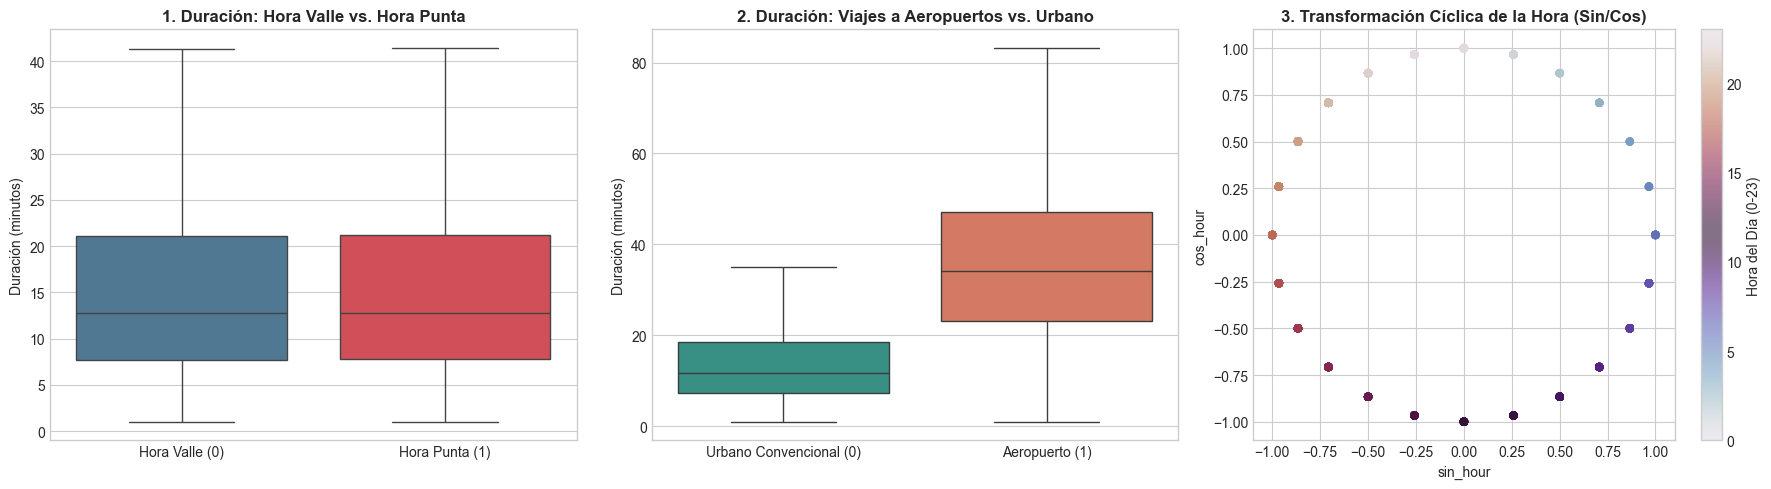

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico 1: Duración en Hora Punta vs Hora Valle
sns.boxplot(
    data=df_features, 
    x='is_rush_hour', 
    y='trip_duration', 
    palette=['#457b9d', '#e63946'], 
    showfliers=False, 
    ax=axes[0]
)
axes[0].set_xticklabels(['Hora Valle (0)', 'Hora Punta (1)'])
axes[0].set_title('1. Duración: Hora Valle vs. Hora Punta', fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('Duración (minutos)')

# Gráfico 2: Duración según viaje a Aeropuerto
sns.boxplot(
    data=df_features, 
    x='is_airport', 
    y='trip_duration', 
    palette=['#2a9d8f', '#e76f51'], 
    showfliers=False, 
    ax=axes[1]
)
axes[1].set_xticklabels(['Urbano Convencional (0)', 'Aeropuerto (1)'])
axes[1].set_title('2. Duración: Viajes a Aeropuertos vs. Urbano', fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('Duración (minutos)')

# Gráfico 3: Visualización de Features Cíclicas
scatter = axes[2].scatter(
    df_features['sin_hour'].iloc[:2000], 
    df_features['cos_hour'].iloc[:2000], 
    c=df_features['pickup_hour'].iloc[:2000], 
    cmap='twilight', 
    alpha=0.6, 
    s=25
)
fig.colorbar(scatter, ax=axes[2], label='Hora del Día (0-23)')
axes[2].set_title('3. Transformación Cíclica de la Hora (Sin/Cos)', fontweight='bold')
axes[2].set_xlabel('sin_hour')
axes[2].set_ylabel('cos_hour')

plt.tight_layout()
plt.show()

## 2.7. Exportación del Dataset Procesado para Modelado
Guardamos el dataset limpio y con variables agregadas dentro de `data/processed/`. El modelado se realizará a partir de este dataset

In [25]:
output_dir = get_data_dir('processed')
os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(output_dir, 'yellow_tripdata_processed.parquet')
df_features.to_parquet(output_path, index=False)

print(f'Archivo guardado con éxito en: {output_path}')

Archivo guardado con éxito en: ..\data\processed\yellow_tripdata_processed.parquet
